In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.calibration import (
    CalibratedClassifierCV,
    CalibrationDisplay
)
from sklearn.metrics import (
    brier_score_loss,
    log_loss,
    roc_auc_score
)

static_profile = pd.read_csv(
    "C:/Users/lenovo/Desktop/FinRisk-X/data/processed/customer_financial_profile.csv"
)

risk_fusion = pd.read_csv(
    "C:/Users/lenovo/Desktop/FinRisk-X/data/processed/final_risk_scores_explainable.csv"
)

credit_model = joblib.load(
    "C:/Users/lenovo/Desktop/FinRisk-X/models/credit_risk_xgb.pkl"
)

credit_features = joblib.load(
    "C:/Users/lenovo/Desktop/FinRisk-X/models/credit_risk_features.pkl"
)

print("Files loaded successfully.")

Files loaded successfully.


In [2]:
X = static_profile[credit_features].copy()

X = (
    X
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

y = static_profile["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Default rate:", y.mean())

Training rows: 8000
Testing rows: 2000
Default rate: 0.3219


In [3]:
original_probability = credit_model.predict_proba(
    X_test
)[:, 1]

print("Original probability range:")
print(
    original_probability.min(),
    "to",
    original_probability.max()
)

Original probability range:
0.01942026 to 0.93333805


In [6]:
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV

# Clone the trained credit model
calibration_base_model = clone(credit_model)

calibrated_model = CalibratedClassifierCV(
    estimator=calibration_base_model,
    method="sigmoid",
    cv=5
)

calibrated_model.fit(
    X_train,
    y_train
)

calibrated_probability = calibrated_model.predict_proba(
    X_test
)[:, 1]

print("Calibration completed successfully.")
print(
    "Calibrated probability range:",
    calibrated_probability.min(),
    "to",
    calibrated_probability.max()
)

Calibration completed successfully.
Calibrated probability range: 0.14452308146969717 to 0.7711703426336355


In [7]:
calibrated_probability = calibrated_model.predict_proba(
    X_test
)[:, 1]

print("Calibrated probability range:")
print(
    calibrated_probability.min(),
    "to",
    calibrated_probability.max()
)

Calibrated probability range:
0.14452308146969717 to 0.7711703426336355


In [8]:
original_brier = brier_score_loss(
    y_test,
    original_probability
)

calibrated_brier = brier_score_loss(
    y_test,
    calibrated_probability
)

original_logloss = log_loss(
    y_test,
    original_probability
)

calibrated_logloss = log_loss(
    y_test,
    calibrated_probability
)

original_auc = roc_auc_score(
    y_test,
    original_probability
)

calibrated_auc = roc_auc_score(
    y_test,
    calibrated_probability
)

comparison = pd.DataFrame({
    "model": [
        "Original XGBoost",
        "Calibrated XGBoost"
    ],
    "brier_score": [
        original_brier,
        calibrated_brier
    ],
    "log_loss": [
        original_logloss,
        calibrated_logloss
    ],
    "roc_auc": [
        original_auc,
        calibrated_auc
    ]
})

comparison

,model,brier_score,log_loss,roc_auc
0,Original XGBoost,0.202814,0.595829,0.672701
1,Calibrated XGBoost,0.198949,0.584334,0.677251


In [9]:
comparison.to_csv(
    "../data/processed/calibration_comparison.csv",
    index=False
)

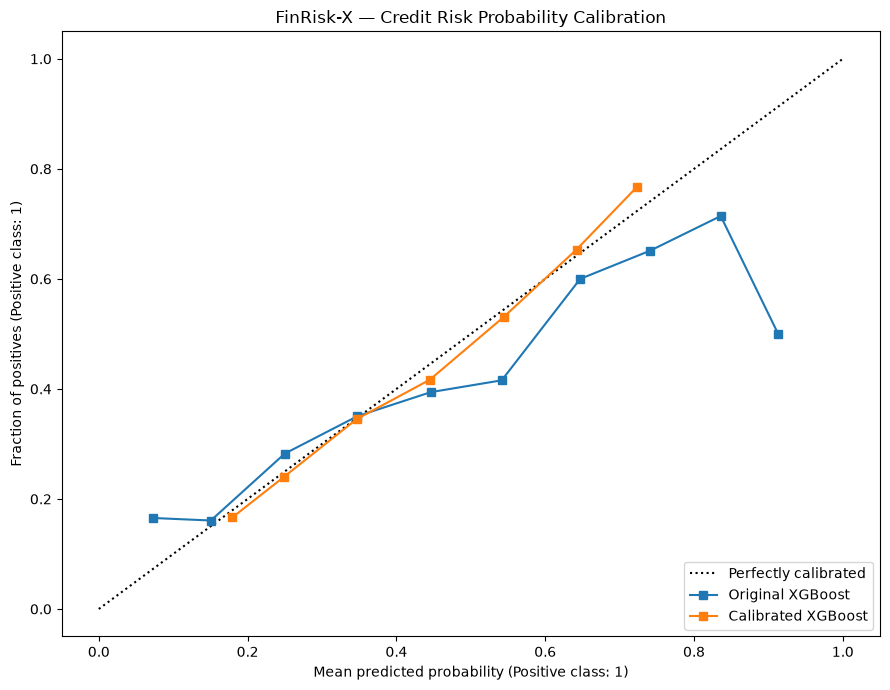

In [10]:
fig, ax = plt.subplots(figsize=(9, 7))

CalibrationDisplay.from_predictions(
    y_test,
    original_probability,
    n_bins=10,
    name="Original XGBoost",
    ax=ax
)

CalibrationDisplay.from_predictions(
    y_test,
    calibrated_probability,
    n_bins=10,
    name="Calibrated XGBoost",
    ax=ax
)

ax.set_title(
    "FinRisk-X — Credit Risk Probability Calibration"
)

plt.tight_layout()

plt.savefig(
    "../reports/figures/credit_probability_calibration.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

In [11]:
uncertainty = (
    1 - 2 * np.abs(calibrated_probability - 0.5)
)

confidence = 1 - uncertainty

print("Uncertainty range:")
print(uncertainty.min(), "to", uncertainty.max())

print("\nConfidence range:")
print(confidence.min(), "to", confidence.max())

Uncertainty range:
0.28904616293939434 to 0.9997234330740319

Confidence range:
0.0002765669259681136 to 0.7109538370606057


In [12]:
uncertainty_category = pd.cut(
    uncertainty,
    bins=[
        -np.inf,
        0.20,
        0.40,
        np.inf
    ],
    labels=[
        "Low Uncertainty",
        "Moderate Uncertainty",
        "High Uncertainty"
    ]
)

uncertainty_category.value_counts()

Low Uncertainty            0
Moderate Uncertainty     282
High Uncertainty        1718
Name: count, dtype: int64

In [15]:
uncertainty_results = X_test.copy()

uncertainty_results["customer_id"] = (
    static_profile.loc[X_test.index, "customer_id"].to_numpy()
)

uncertainty_results["actual_default"] = y_test.to_numpy()

uncertainty_results["original_probability"] = (
    original_probability
)

uncertainty_results["calibrated_probability"] = (
    calibrated_probability
)

uncertainty_results["uncertainty_score"] = (
    uncertainty
)

uncertainty_results["confidence_score"] = (
    confidence
)

uncertainty_results["uncertainty_category"] = (
    uncertainty_category.astype(str).to_numpy()
)

uncertainty_results.head()

,age,annual_income,employment_years,dependents,savings,existing_debt,credit_score,total_loans,total_loan_amount,average_interest_rate,...,debt_to_income,payment_to_income,savings_to_loan,customer_id,actual_default,original_probability,calibrated_probability,uncertainty_score,confidence_score,uncertainty_category
1372,27,7.086079e+05,15,0,447103.503631,534019.971172,0.870801,1.0,207228.0,6.190000,...,0.117850,0.028200,0.108657,101373,0,0.558092,0.433522,0.867045,0.132955,High Uncertainty
3579,47,1.157078e+06,11,0,249288.776426,217387.810661,0.408269,1.0,513879.0,9.270000,...,0.028940,0.032993,0.024431,103580,0,0.392231,0.397479,0.794957,0.205043,High Uncertainty
5387,56,3.416194e+05,1,2,208143.071712,83174.900649,0.514212,4.0,937805.0,9.495000,...,0.037677,0.360384,0.011178,105388,1,0.274926,0.270531,0.541063,0.458937,High Uncertainty
2282,55,6.654880e+05,16,0,307847.391599,163935.699985,0.573643,3.0,1808518.0,8.713333,...,0.038128,0.323604,0.008573,102283,1,0.253215,0.276488,0.552976,0.447024,High Uncertainty
2595,52,4.241303e+05,20,3,168903.643869,685712.104385,0.485788,0.0,0.0,0.000000,...,0.253497,0.000000,0.000000,102596,1,0.792444,0.666172,0.667656,0.332344,High Uncertainty


In [16]:
uncertainty_results["human_review_required"] = (
    uncertainty_results["uncertainty_score"] >= 0.40
)

uncertainty_results["decision"] = np.select(
    [
        uncertainty_results["calibrated_probability"] < 0.25,
        uncertainty_results["calibrated_probability"] < 0.50,
        uncertainty_results["calibrated_probability"] < 0.75
    ],
    [
        "Approve",
        "Review",
        "High Risk Review"
    ],
    default="Reject or Escalate"
)

uncertainty_results[
    [
        "customer_id",
        "calibrated_probability",
        "uncertainty_score",
        "confidence_score",
        "uncertainty_category",
        "human_review_required",
        "decision"
    ]
].head(10)

,customer_id,calibrated_probability,uncertainty_score,confidence_score,uncertainty_category,human_review_required,decision
1372,101373,0.433522,0.867045,0.132955,High Uncertainty,True,Review
3579,103580,0.397479,0.794957,0.205043,High Uncertainty,True,Review
5387,105388,0.270531,0.541063,0.458937,High Uncertainty,True,Review
2282,102283,0.276488,0.552976,0.447024,High Uncertainty,True,Review
2595,102596,0.666172,0.667656,0.332344,High Uncertainty,True,High Risk Review
8533,108534,0.628671,0.742658,0.257342,High Uncertainty,True,High Risk Review
1692,101693,0.205732,0.411464,0.588536,High Uncertainty,True,Approve
7209,107210,0.251470,0.502941,0.497059,High Uncertainty,True,Review
4669,104670,0.255015,0.510029,0.489971,High Uncertainty,True,Review
3950,103951,0.322235,0.644469,0.355531,High Uncertainty,True,Review


In [17]:
all_calibrated_probability = calibrated_model.predict_proba(
    X
)[:, 1]

all_uncertainty = (
    1 - 2 * np.abs(all_calibrated_probability - 0.5)
)

all_confidence = 1 - all_uncertainty

calibrated_customer_data = pd.DataFrame({
    "customer_id": static_profile["customer_id"],
    "calibrated_credit_probability": (
        all_calibrated_probability
    ),
    "credit_uncertainty_score": all_uncertainty,
    "credit_confidence_score": all_confidence
})

In [18]:
calibrated_customer_data["credit_uncertainty_category"] = pd.cut(
    calibrated_customer_data["credit_uncertainty_score"],
    bins=[
        -np.inf,
        0.20,
        0.40,
        np.inf
    ],
    labels=[
        "Low Uncertainty",
        "Moderate Uncertainty",
        "High Uncertainty"
    ]
).astype(str)

calibrated_customer_data["human_review_required"] = (
    calibrated_customer_data["credit_uncertainty_score"] >= 0.40
)

In [19]:
risk_with_uncertainty = risk_fusion.merge(
    calibrated_customer_data,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

risk_with_uncertainty.head()

,customer_id,credit_risk_probability,credit_risk_score,temporal_risk_probability,temporal_risk_score,avg_fraud_probability,max_fraud_probability,avg_anomaly_score,max_anomaly_score,avg_hybrid_fraud_score,...,finrisk_score,risk_category,reason_1,reason_2,reason_3,calibrated_credit_probability,credit_uncertainty_score,credit_confidence_score,credit_uncertainty_category,human_review_required
0,100001,0.393545,39.354540,0.351935,35.193510,0.262764,0.783083,0.185125,0.816251,0.239472,...,38.242348,Moderate,employment_years increased risk,savings_to_loan reduced risk,total_spending reduced risk,0.367032,0.734065,0.265935,High Uncertainty,True
1,100002,0.665469,66.546906,0.315314,31.531355,0.313527,0.803767,0.221139,0.709282,0.285810,...,46.359409,Moderate,employment_years increased risk,savings increased risk,payment_to_income increased risk,0.549241,0.901517,0.098483,High Uncertainty,True
2,100003,0.515152,51.515220,0.410704,41.070427,0.476873,0.783061,0.261322,0.502814,0.412207,...,45.627977,Moderate,credit_score increased risk,debt_to_income reduced risk,savings reduced risk,0.451192,0.902384,0.097616,High Uncertainty,True
3,100004,0.411317,41.131725,0.357690,35.768967,0.266366,0.797005,0.227899,0.488348,0.254826,...,40.674674,Moderate,debt_to_income reduced risk,total_spending increased risk,annual_income increased risk,0.364358,0.728716,0.271284,High Uncertainty,True
4,100005,0.573910,57.391030,0.325702,32.570225,0.295973,0.812917,0.247687,0.494577,0.281487,...,43.396794,Moderate,debt_to_income increased risk,existing_debt increased risk,savings reduced risk,0.434674,0.869349,0.130651,High Uncertainty,True


In [20]:
risk_with_uncertainty.to_csv(
    "../data/processed/final_risk_scores_uncertainty_aware.csv",
    index=False
)

joblib.dump(
    calibrated_model,
    "../models/calibrated_credit_risk_model.pkl"
)

print("Uncertainty-aware risk dataset saved.")
print("Calibrated model saved.")

Uncertainty-aware risk dataset saved.
Calibrated model saved.


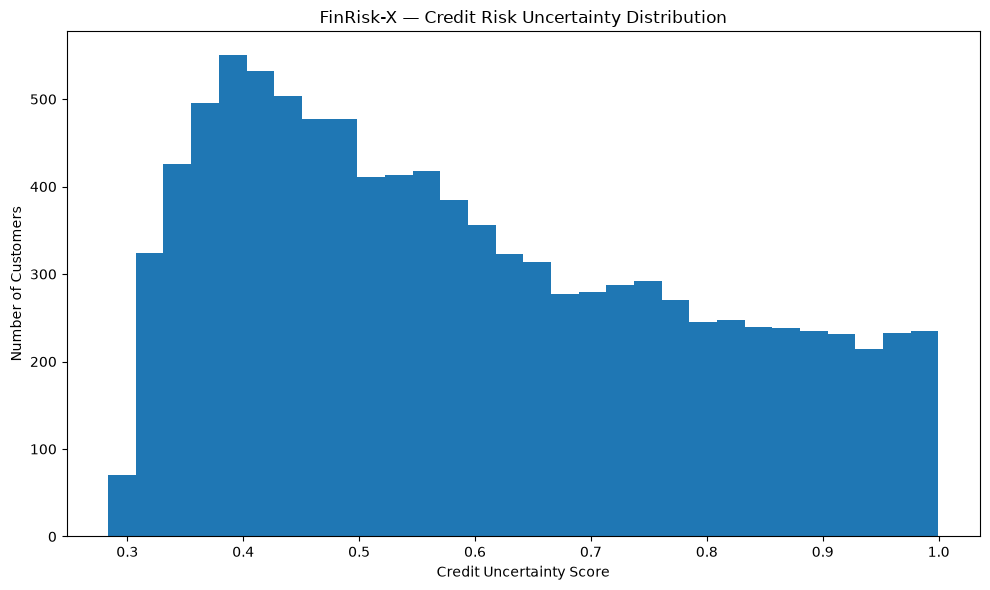

In [21]:
plt.figure(figsize=(10, 6))

plt.hist(
    risk_with_uncertainty["credit_uncertainty_score"],
    bins=30
)

plt.xlabel("Credit Uncertainty Score")
plt.ylabel("Number of Customers")
plt.title(
    "FinRisk-X — Credit Risk Uncertainty Distribution"
)

plt.tight_layout()

plt.savefig(
    "../reports/figures/credit_uncertainty_distribution.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

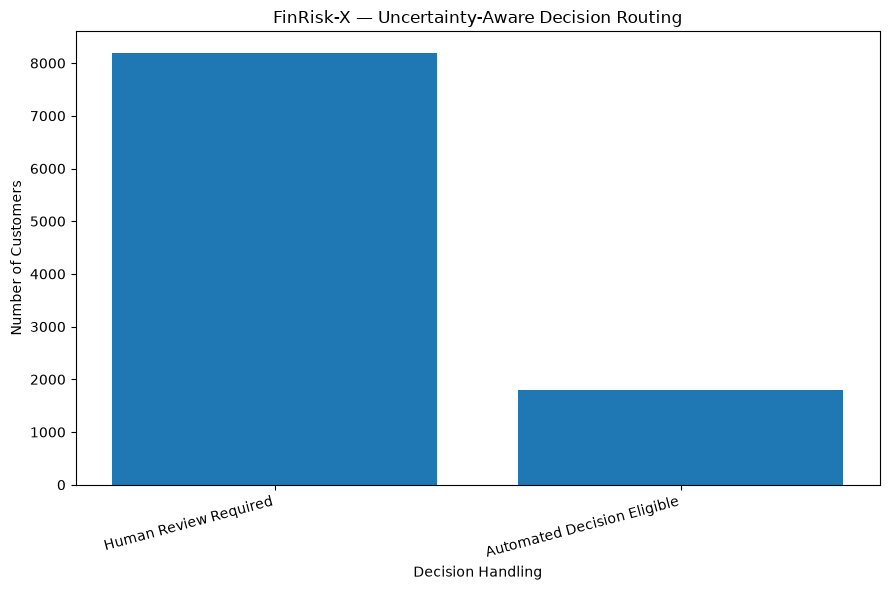

In [22]:
review_counts = (
    risk_with_uncertainty["human_review_required"]
    .map({
        True: "Human Review Required",
        False: "Automated Decision Eligible"
    })
    .value_counts()
)

plt.figure(figsize=(9, 6))

plt.bar(
    review_counts.index,
    review_counts.values
)

plt.xlabel("Decision Handling")
plt.ylabel("Number of Customers")
plt.title(
    "FinRisk-X — Uncertainty-Aware Decision Routing"
)

plt.xticks(rotation=15, ha="right")
plt.tight_layout()

plt.savefig(
    "../reports/figures/human_review_routing.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

In [23]:
print("=" * 60)
print("FinRisk-X — Phase 12 Validation")
print("=" * 60)

print("\nCustomers:", len(risk_with_uncertainty))

print("\nCalibration comparison:")
print(comparison)

print("\nUncertainty categories:")
print(
    risk_with_uncertainty[
        "credit_uncertainty_category"
    ].value_counts()
)

print("\nHuman review counts:")
print(
    risk_with_uncertainty[
        "human_review_required"
    ].value_counts()
)

print("\nMissing values:")
print(
    risk_with_uncertainty[
        [
            "calibrated_credit_probability",
            "credit_uncertainty_score",
            "credit_confidence_score",
            "credit_uncertainty_category"
        ]
    ].isna().sum()
)

print("\n" + "=" * 60)
print("PHASE 12 COMPLETE")
print("=" * 60)

FinRisk-X — Phase 12 Validation

Customers: 10000

Calibration comparison:
                model  brier_score  log_loss   roc_auc
0    Original XGBoost     0.202814  0.595829  0.672701
1  Calibrated XGBoost     0.198949  0.584334  0.677251

Uncertainty categories:
credit_uncertainty_category
High Uncertainty        8193
Moderate Uncertainty    1807
Name: count, dtype: int64

Human review counts:
human_review_required
True     8193
False    1807
Name: count, dtype: int64

Missing values:
calibrated_credit_probability    0
credit_uncertainty_score         0
credit_confidence_score          0
credit_uncertainty_category      0
dtype: int64

PHASE 12 COMPLETE
